In [3]:
# import thư viện
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
# Đọc dữ liệu đã tiền xử lý
df = pd.read_csv("../data/processed/appliances_processed.csv")
print("Kích thước dữ liệu: ", df.shape)
print("\n5 dòng đầu tiên của dữ liệu:")
display(df.head())

Kích thước dữ liệu:  (19732, 34)

5 dòng đầu tiên của dữ liệu:


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour,day_of_week,is_weekend,lag_1,rolling_mean
0,2016-01-11 17:30:00,50,40,19.890000,46.066667,19.2,44.59,19.79,45.000000,18.89,...,6.000000,51.500000,5.000000,45.410389,45.410389,17,0,0,50.0,56.666667
1,2016-01-11 17:40:00,60,40,19.890000,46.333333,19.2,44.53,19.79,45.000000,18.89,...,5.666667,47.666667,4.900000,10.084097,10.084097,17,0,0,50.0,53.333333
2,2016-01-11 17:50:00,50,40,19.890000,46.026667,19.2,44.50,19.79,44.933333,18.89,...,5.333333,43.833333,4.800000,44.919484,44.919484,17,0,0,60.0,53.333333
3,2016-01-11 18:00:00,60,50,19.890000,45.766667,19.2,44.50,19.79,44.900000,18.89,...,5.000000,40.000000,4.700000,47.233763,47.233763,18,0,0,50.0,53.333333
4,2016-01-11 18:10:00,60,50,19.856667,45.560000,19.2,44.50,19.73,44.900000,18.89,...,5.166667,40.000000,4.683333,33.039890,33.039890,18,0,0,60.0,56.666667


In [5]:
# Xác định biến đầu vào và biến mục tiêu
target = "Appliances"
X = df.drop(columns=[target, "date"])
Y = df[target]
print("Số lượng đặc trưng đầu vào: ", X.shape[1])
print("Số lượng mẫu: ", X.shape[0])
print("Biến mục tiêu: ", target)
display(X.head())


Số lượng đặc trưng đầu vào:  32
Số lượng mẫu:  19732
Biến mục tiêu:  Appliances


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour,day_of_week,is_weekend,lag_1,rolling_mean
0,40,19.890000,46.066667,19.2,44.59,19.79,45.000000,18.89,45.723333,17.166667,...,6.000000,51.500000,5.000000,45.410389,45.410389,17,0,0,50.0,56.666667
1,40,19.890000,46.333333,19.2,44.53,19.79,45.000000,18.89,45.530000,17.200000,...,5.666667,47.666667,4.900000,10.084097,10.084097,17,0,0,50.0,53.333333
2,40,19.890000,46.026667,19.2,44.50,19.79,44.933333,18.89,45.730000,17.133333,...,5.333333,43.833333,4.800000,44.919484,44.919484,17,0,0,60.0,53.333333
3,50,19.890000,45.766667,19.2,44.50,19.79,44.900000,18.89,45.790000,17.100000,...,5.000000,40.000000,4.700000,47.233763,47.233763,18,0,0,50.0,53.333333
4,50,19.856667,45.560000,19.2,44.50,19.73,44.900000,18.89,45.863333,17.100000,...,5.166667,40.000000,4.683333,33.039890,33.039890,18,0,0,60.0,56.666667


In [6]:
# Chia dữ liệu Train và Test theo thời gian
split_index = int(len(X) * 0.8)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
Y_train = Y.iloc[:split_index]
Y_test = Y.iloc[split_index:]
print("Số mẫu Train:", len(X_train))
print("Số mẫu Test:", len(X_test))
print("Tỷ lệ Train:", len(X_train) / len(X) * 100, "%")
print("Tỷ lệ Test:", len(X_test) / len(X) * 100, "%")

Số mẫu Train: 15785
Số mẫu Test: 3947
Tỷ lệ Train: 79.99695925400366 %
Tỷ lệ Test: 20.00304074599635 %


In [7]:
# Xây dựng mô hình Baseline
from sklearn.dummy import DummyRegressor
# Khởi tạo mô hình
baseline = DummyRegressor(strategy="mean")
# Huấn luyện mô hình
baseline.fit(X_train, Y_train)
# Dự đoán trên tập Test
Y_pred_baseline = baseline.predict(X_test)
print("Huấn luyện Baseline thành công!")

Huấn luyện Baseline thành công!


In [8]:
# Đánh giá mô hình Baseline
mae = mean_absolute_error(Y_test, Y_pred_baseline)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred_baseline))
r2 = r2_score(Y_test, Y_pred_baseline)
print("KẾT QUẢ BASELINE")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2:", round(r2, 3))

KẾT QUẢ BASELINE
MAE: 52.689
RMSE: 91.054
R2: -0.0


In [9]:
# Huấn luyện mô hình Linear Regression
linear_model = LinearRegression()
# Huấn luyện
linear_model.fit(X_train, Y_train)
# Dự đoán
Y_pred_linear = linear_model.predict(X_test)
print("Huấn luyện Linear Regression thành công!")

Huấn luyện Linear Regression thành công!


In [10]:
# 8. Đánh giá Linear Regression
mae_linear = mean_absolute_error(Y_test, Y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(Y_test, Y_pred_linear))
r2_linear = r2_score(Y_test, Y_pred_linear)
print("KẾT QUẢ LINEAR REGRESSION")
print("MAE:", round(mae_linear, 3))
print("RMSE:", round(rmse_linear, 3))
print("R2:", round(r2_linear, 3))

KẾT QUẢ LINEAR REGRESSION
MAE: 29.01
RMSE: 62.005
R2: 0.536


In [11]:
# So sánh Baseline và Linear Regression
comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(Y_test, Y_pred_baseline),
        mae_linear
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(Y_test, Y_pred_baseline)),
        rmse_linear
    ],
    "R2": [
        r2_score(Y_test, Y_pred_baseline),
        r2_linear
    ]
})

display(comparison)

,Model,MAE,RMSE,R2
0,Baseline,52.688640,91.053578,-0.000331
1,Linear Regression,29.010182,62.005309,0.536118


In [12]:
# Huấn luyện mô hình Ridge Regression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, Y_train)

Y_pred_ridge = ridge_model.predict(X_test)

print("Huấn luyện Ridge Regression thành công!")

Huấn luyện Ridge Regression thành công!


In [13]:
# Đánh giá Ridge Regression

mae_ridge = mean_absolute_error(Y_test, Y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(Y_test, Y_pred_ridge))
r2_ridge = r2_score(Y_test, Y_pred_ridge)

print("KẾT QUẢ RIDGE REGRESSION")
print("MAE:", round(mae_ridge, 3))
print("RMSE:", round(rmse_ridge, 3))
print("R2:", round(r2_ridge, 3))

KẾT QUẢ RIDGE REGRESSION
MAE: 29.012
RMSE: 62.005
R2: 0.536


In [14]:
# So sánh các mô hình

comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression", "Ridge Regression"],
    "MAE": [
        mean_absolute_error(Y_test, Y_pred_baseline),
        mae_linear,
        mae_ridge
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(Y_test, Y_pred_baseline)),
        rmse_linear,
        rmse_ridge
    ],
    "R2": [
        r2_score(Y_test, Y_pred_baseline),
        r2_linear,
        r2_ridge
    ]
})

display(comparison)

,Model,MAE,RMSE,R2
0,Baseline,52.688640,91.053578,-0.000331
1,Linear Regression,29.010182,62.005309,0.536118
2,Ridge Regression,29.011724,62.005464,0.536116


In [15]:
# Huấn luyện Random Forest Regression

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Huấn luyện mô hình
rf_model.fit(X_train, Y_train)

# Dự đoán
Y_pred_rf = rf_model.predict(X_test)

print("Huấn luyện Random Forest thành công!")

Huấn luyện Random Forest thành công!


In [16]:
# Đánh giá Random Forest

mae_rf = mean_absolute_error(Y_test, Y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(Y_test, Y_pred_rf))
r2_rf = r2_score(Y_test, Y_pred_rf)

print("KẾT QUẢ RANDOM FOREST")
print("MAE:", round(mae_rf, 3))
print("RMSE:", round(rmse_rf, 3))
print("R2:", round(r2_rf, 3))

KẾT QUẢ RANDOM FOREST
MAE: 77.332
RMSE: 114.374
R2: -0.578


In [17]:
# So sánh 4 mô hình

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Random Forest"
    ],
    "MAE": [
        mean_absolute_error(Y_test, Y_pred_baseline),
        mae_linear,
        mae_ridge,
        mae_rf
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(Y_test, Y_pred_baseline)),
        rmse_linear,
        rmse_ridge,
        rmse_rf
    ],
    "R2": [
        r2_score(Y_test, Y_pred_baseline),
        r2_linear,
        r2_ridge,
        r2_rf
    ]
})

display(comparison)

,Model,MAE,RMSE,R2
0,Baseline,52.688640,91.053578,-0.000331
1,Linear Regression,29.010182,62.005309,0.536118
2,Ridge Regression,29.011724,62.005464,0.536116
3,Random Forest,77.332475,114.373797,-0.578347


In [18]:
# Huấn luyện Gradient Boosting Regression

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Huấn luyện
gb_model.fit(X_train, Y_train)

# Dự đoán
Y_pred_gb = gb_model.predict(X_test)

print("Huấn luyện Gradient Boosting thành công!")

Huấn luyện Gradient Boosting thành công!


In [19]:
# Đánh giá Gradient Boosting

mae_gb = mean_absolute_error(Y_test, Y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(Y_test, Y_pred_gb))
r2_gb = r2_score(Y_test, Y_pred_gb)

print("KẾT QUẢ GRADIENT BOOSTING")
print("MAE:", round(mae_gb, 3))
print("RMSE:", round(rmse_gb, 3))
print("R2:", round(r2_gb, 3))

KẾT QUẢ GRADIENT BOOSTING
MAE: 110.903
RMSE: 144.916
R2: -1.534


In [20]:
# Bảng so sánh kết quả

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mean_absolute_error(Y_test, Y_pred_baseline),
        mae_linear,
        mae_ridge,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(Y_test, Y_pred_baseline)),
        rmse_linear,
        rmse_ridge,
        rmse_rf,
        rmse_gb
    ],
    "R2": [
        r2_score(Y_test, Y_pred_baseline),
        r2_linear,
        r2_ridge,
        r2_rf,
        r2_gb
    ]
})

display(comparison.sort_values(by="RMSE"))

,Model,MAE,RMSE,R2
1,Linear Regression,29.010182,62.005309,0.536118
2,Ridge Regression,29.011724,62.005464,0.536116
0,Baseline,52.688640,91.053578,-0.000331
3,Random Forest,77.332475,114.373797,-0.578347
4,Gradient Boosting,110.902914,144.916317,-1.533869


In [21]:
display(comparison.sort_values(by="RMSE"))

,Model,MAE,RMSE,R2
1,Linear Regression,29.010182,62.005309,0.536118
2,Ridge Regression,29.011724,62.005464,0.536116
0,Baseline,52.688640,91.053578,-0.000331
3,Random Forest,77.332475,114.373797,-0.578347
4,Gradient Boosting,110.902914,144.916317,-1.533869


In [22]:
# Chọn mô hình tốt nhất
best_model = LinearRegression()

# Huấn luyện mô hình
best_model.fit(X_train, Y_train)

print("Best model: Linear Regression")

Best model: Linear Regression


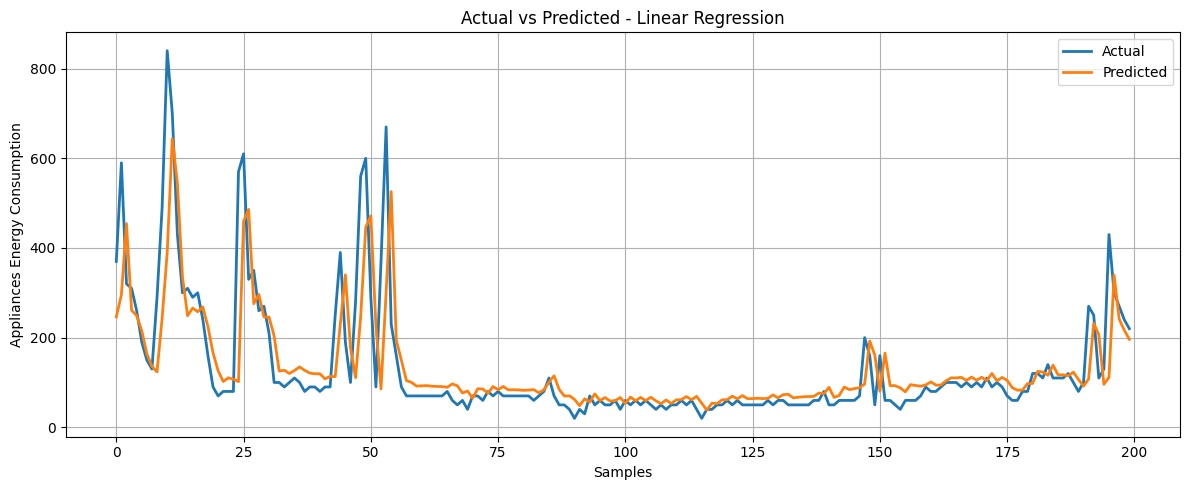

In [23]:
import matplotlib.pyplot as plt

# Dự đoán bằng Linear Regression
Y_pred = best_model.predict(X_test)

# Vẽ biểu đồ
plt.figure(figsize=(12, 5))

plt.plot(
    Y_test.values[:200],
    label="Actual",
    linewidth=2
)

plt.plot(
    Y_pred[:200],
    label="Predicted",
    linewidth=2
)

plt.title("Actual vs Predicted - Linear Regression")
plt.xlabel("Samples")
plt.ylabel("Appliances Energy Consumption")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("../images/actual_vs_predicted.png",
            dpi=300, bbox_inches="tight")
plt.show()

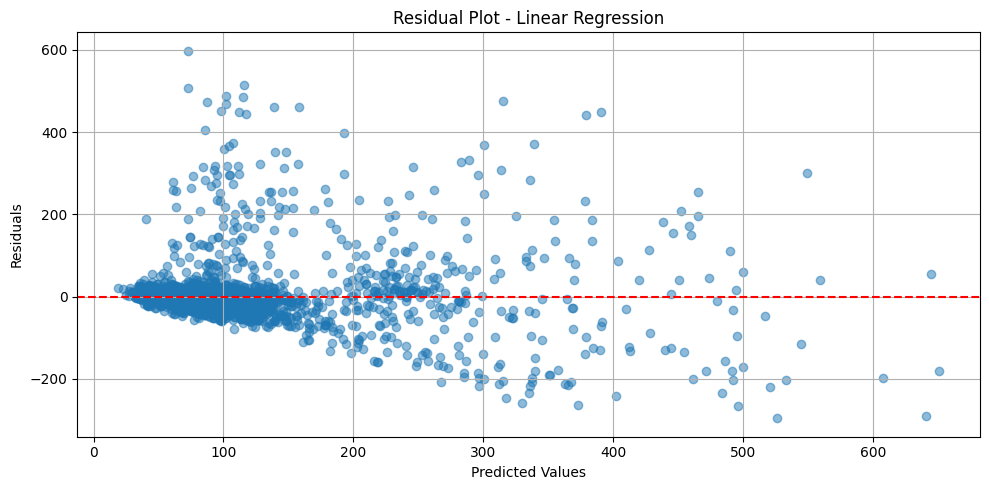

In [24]:
# Tính sai số dự đoán
residuals = Y_test.values - Y_pred

# Vẽ biểu đồ sai số
plt.figure(figsize=(10, 5))

plt.scatter(Y_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residual Plot - Linear Regression")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.grid(True)
plt.tight_layout()
plt.savefig("../images/residual_plot.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [25]:
import os
import joblib

# Tạo thư mục models nếu chưa có
os.makedirs("../models", exist_ok=True)

# Lưu mô hình
joblib.dump(best_model, "../models/best_model.pkl")

print("Đã lưu mô hình thành công!")

Đã lưu mô hình thành công!


## KẾT LUẬN VÀ SO SÁNH MÔ HÌNH

Sau quá trình huấn luyện và đánh giá 5 mô hình, thu được kết quả:

- Linear Regression đạt MAE = 29.010, RMSE = 62.005, R² = 0.536.
- Ridge Regression có kết quả gần tương đương Linear Regression.
- Baseline có kết quả thấp hơn hai mô hình trên.
- Random Forest và Gradient Boosting cho kết quả chưa tốt trên tập kiểm tra.

Linear Regression được lựa chọn làm mô hình tốt nhất vì có MAE và RMSE thấp nhất, đồng thời có R² cao nhất.

Mô hình này sẽ được sử dụng cho bước dự đoán và đánh giá tiếp theo.